# 13 · 负采样、BPR 与 LightGCN
## 目标
亲自抽三元组 `(user, positive, unknown)`，看图传播的张量，再运行一个小训练。
这不是把人工张量包装成竞赛效果：机制演示会明确标识，训练使用真实 t1 历史。
## 准备
[模型和训练循环](../reclab/competition/graph.py) · [冠军原模型](../data/xmrec/upstream/winner/src/retrieval/lgcn_v2/model.py)。

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd()
if not (ROOT / "reclab").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code
from reclab.competition import data
from reclab.competition.teaching import load_run, style, bar_scores
style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
run, rows, features = load_run()
print("实际训练快照:", run.name)

实际训练快照: 20261030T115556803593-cloud-restore


## 步骤 1 · 抽样规则就是模型假设
先均匀选用户，再从其已知历史中均匀选正例，从未见商品里拒绝采样负例。
这些“负例”只是未知项，可能含未来喜欢的商品。`negative_power=.75` 改为按热度的 .75 次幂抽样；它与均匀抽样优化的分布不同。

In [2]:
from reclab.competition.data import encode
from reclab.competition.graph import NegativeSampler, normalized_graph, LightGCN, GraphConfig, train_graph, graph_score
import torch
real = data.corpus(["t1"])
users, items, history = encode(real)
history.data[:] = 1
draws = {}
for power in [0., .75]:
    sampler = NegativeSampler(history, power=power, seed=2022)
    u, p, n = sampler.sample(20000)
    assert sampler.is_known(u, p).all() and not sampler.is_known(u, n).any()
    popularity = np.asarray(history.sum(axis=0)).ravel()
    draws[power] = popularity[n]
    print("power:", power, "负例平均训练热度:", round(float(popularity[n].mean()), 2))
display(pd.DataFrame({"user": users[u[:5]], "positive": items[p[:5]], "sampled_unknown": items[n[:5]]}))

power: 0.0 负例平均训练热度: 17.28
power: 0.75 负例平均训练热度: 121.4


,user,positive,sampled_unknown
0,t1U1007037,P1007562,P1026949
1,t1U1002463,P1009950,P1032560
2,t1U1007458,P1018990,P1022155
3,t1U1000925,P1004032,P1003943
4,t1U1001876,P1004147,P1009057


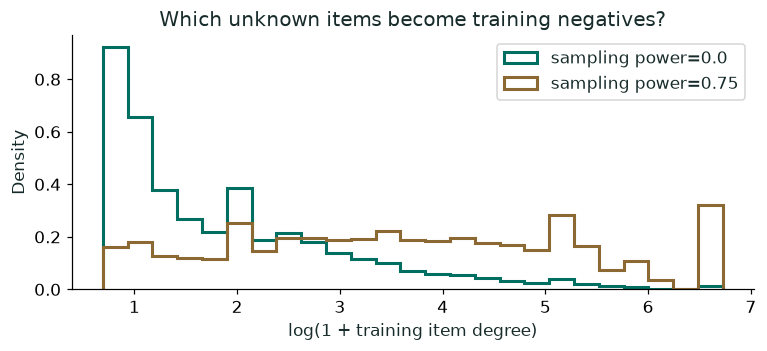

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
for power, values in draws.items():
    ax.hist(np.log1p(values), bins=25, histtype="step", linewidth=2, density=True, label=f"sampling power={power}")
ax.set(xlabel="log(1 + training item degree)", ylabel="Density", title="Which unknown items become training negatives?")
ax.legend(); plt.show()

## 步骤 2 · 构造张量核对传播
下面只有 3 个用户、4 个商品，是**构造的机制演示**。
邻接矩阵 A 在两侧分别连接 user 与 item；归一化 `D^-1/2 A D^-1/2` 后传播。
最终表示是第 0 到 L 层的平均，不含 MLP、非线性和额外特征变换。

In [4]:
from scipy import sparse
toy = sparse.csr_matrix([[1,1,0,0], [0,1,1,0], [0,0,1,1]], dtype=np.float32)
graph = normalized_graph(toy)
torch.manual_seed(2022)
net = LightGCN(3, 4, dim=8, layers=2)
user_vectors, item_vectors = net.propagate(graph)
print("邻接矩阵", tuple(graph.shape), "用户向量", tuple(user_vectors.shape), "商品向量", tuple(item_vectors.shape))
u0, p0, n0 = torch.tensor([0,1]), torch.tensor([0,1]), torch.tensor([3,0])
loss, reg = net.bpr_loss(graph, u0, p0, n0)
loss.backward()
print("BPR:", float(loss.detach()), "ego L2:", float(reg.detach()))
print("Embedding gradient norm:", float(net.item_embedding.weight.grad.norm()))
assert torch.isfinite(net.item_embedding.weight.grad).all()

邻接矩阵 (7, 7) 用户向量 (3, 8) 商品向量 (4, 8)
BPR: 0.6874470710754395 ego L2: 0.1299145221710205
Embedding gradient norm: 0.041438326239585876


## 步骤 3 · 改代码并运行真实训练
这格会实际训练，不覆盖主实验。第一次用 16 维、4 个 epoch，允许你在几十秒内看完整过程。
修改 `layers=0` 可做相同训练预算的 MF 对照；修改 `negative_power=.75` 看采样影响。
BPR loss 下降不保证候选排名上升。修改 .py 后，先运行下格的 reload，再重跑训练格。

In [5]:
import importlib
import reclab.competition.graph as graph_module
importlib.reload(graph_module)
CONFIG = graph_module.GraphConfig(dim=16, layers=2, epochs=4, steps_per_epoch=2, negative_power=0.)
sandbox = graph_module.train_graph(real, CONFIG)
target = data.candidates("t1")
sandbox_scores = graph_module.graph_score(sandbox, target)
from reclab.competition.metrics import evaluate
display(evaluate(target, sandbox_scores))
# 保存到本轮 Notebook 沙盒文件，和主实验分开。
from datetime import datetime, timezone
sandbox_path = data.OUTPUT / "experiments" / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%f") + "-graph")
sandbox_path.mkdir(parents=True)
torch.save({"state_dict": sandbox["model"].state_dict(), "config": sandbox["config"]}, sandbox_path / "model.pt")
(sandbox_path / "trace.json").write_text(json.dumps(sandbox["trace"], indent=2))
print("沙盒保存:", sandbox_path)

LightGCN layers=2 epoch=1: bpr=0.69083


LightGCN layers=2 epoch=2: bpr=0.68599


LightGCN layers=2 epoch=3: bpr=0.67694


LightGCN layers=2 epoch=4: bpr=0.66325


,market,users,ndcg10,hr10
0,t1,2697,0.428107,0.536522
1,combined,2697,0.428107,0.536522


沙盒保存: /Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/artifacts/xmrec/experiments/20261030T115936874041-graph


## 步骤 4 · 回看主实验与资源差异
主实验用完整五市场语料；下图是实际运行保存的训练曲线。
冠军论文配置是 2,048 维、4 层、学习率 .001、dropout .4；本机版是 32 维、2 层、学习率 .01、无 dropout，且只做少量大批次更新。
数值对照证明核心公式一致，不证明训练配方或最终分数相同。

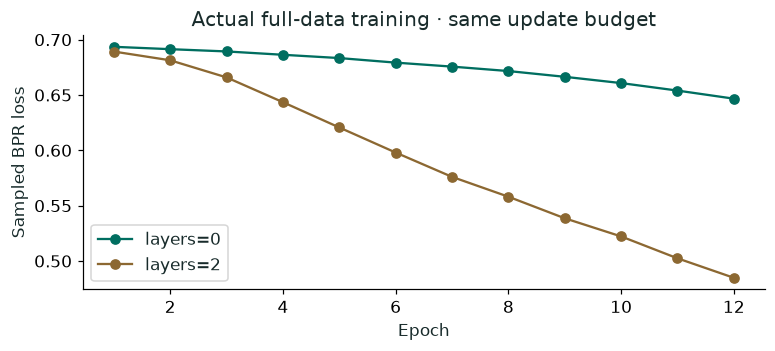

dim                   32.0000
layers                 2.0000
epochs                12.0000
steps_per_epoch        3.0000
batch_size         32768.0000
lr                     0.0100
decay                  0.0001
negative_power         0.0000
seed                2022.0000
threads                4.0000
dtype: float64

In [6]:
trace = json.loads((run / "graph_trace.json").read_text())
fig, ax = plt.subplots(figsize=(8, 3))
for layers, values in trace.items():
    t = pd.DataFrame(values)
    ax.plot(t.epoch, t.bpr, marker="o", label=f"layers={layers}")
ax.set(xlabel="Epoch", ylabel="Sampled BPR loss", title="Actual full-data training · same update budget")
ax.legend(); plt.show()
display(pd.Series(json.loads((run / "config.json").read_text())["graph"]))

## 检查与下一步
为什么 loss 可以很低，官方 100 候选的 nDCG 仍然差？
<details><summary>答案路径</summary>训练负例来自全商品空间，可能太容易；评估候选的分布、训练预算、正例稀疏性和模型容量都会影响排名。要查看相同候选上的指标，不能用 loss 替代。</details>
进入 14，把多个分数交给 LightGBM。